# 02 — Xây dựng đặc trưng

Từ 31,8M giao dịch, ta tạo **105 đặc trưng cho mỗi khách**, chia 4 nhóm:

| Nhóm | Số chiều | Ví dụ | Ý nghĩa |
|---|---|---|---|
| Hành vi giao dịch (RFM + xu hướng) | 24 | `n_txn`, `mean_price`, `recency`, `online_share` | mua bao nhiêu, khi nào, kênh nào |
| Thuộc tính tài khoản | 4 | `club_code`, `news_code` | mức độ gắn kết |
| Tỷ trọng mua theo category | 72 | `index_name__4`, `section_name__0` | mua **nhóm hàng nào** |
| Target encoding theo fold | 9 | `te_article`, `art_enc_std` | "độ tuổi" của món đã mua (notebook 03) |

> Nhóm 4 phụ thuộc nhãn nên được tính **bên trong vòng cross-validation** (notebook 03),
> không nằm trong ma trận tĩnh tạo ở notebook này.

In [1]:
import sys
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

# Notebook có thể được mở từ thư mục notebooks/ hoặc từ gốc repo
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

CUSTOMERS = ROOT / "customers.csv"
ARTICLES = ROOT / "articles.csv"
TXN = ROOT / "transactions_train.csv"
ARTIFACTS = ROOT / "artifacts"
OUTPUTS = ROOT / "outputs"

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.3})
print("polars", pl.__version__, "| numpy", np.__version__, "| ROOT =", ROOT)

polars 2.1.0 | numpy 2.3.5 | ROOT = E:\download\age_imputation


In [2]:
import json

from scipy import sparse

import src.config as C
from src.features import base_features, category_counts, cust_article_matrix, level_counts

customers = pl.read_parquet(C.ARTIFACTS / "customers_base.parquet")
articles_enc = pl.read_parquet(C.ARTIFACTS / "articles_encoded.parquet")

base = base_features(customers)
base.write_parquet(C.ARTIFACTS / "customer_base_features.parquet")
print(f"base features: {base.shape}")
print("cột:", [c for c in base.columns if c != "cust_int"])

base features: (1371980, 28)
cột: ['active_flag', 'Active', 'n_txn', 'n_uniq_art', 'total_spend', 'mean_price', 'median_price', 'max_price', 'std_price', 'n_days', 'online_share', 'weekend_share', 'n_txn_365d', 'mean_price_365d', 'n_txn_90d', 'postal_size', 'recency', 'tenure', 'txn_per_active_day', 'repeat_item_ratio', 'spend_per_txn', 'recent_activity_ratio', 'price_trend', 'log_total_spend', 'log_postal_size', 'club_code', 'news_code']


### Nhóm 1 — Hành vi giao dịch

Các feature đáng chú ý và lý do tạo ra chúng:

| Feature | Công thức | Kỳ vọng |
|---|---|---|
| `n_txn`, `n_uniq_art`, `n_days` | đếm | mức độ hoạt động |
| `total_spend`, `mean_price`, `median_price`, `max_price`, `std_price` | thống kê giá | sức mua; EDA cho thấy ρ(giá, tuổi) ≈ 0,13 |
| `recency` | `MAX_DAY - last_day` | khách còn hoạt động? |
| `tenure` | `last_day - first_day` | quan hệ với shop bao lâu |
| `online_share` | tỷ lệ `sales_channel_id == 2` | thói quen kênh mua |
| `weekend_share` | tỷ lệ mua cuối tuần | thói quen thời gian |
| `n_txn_365d`, `n_txn_90d`, `mean_price_365d` | cửa sổ gần đây | xu hướng gần đây |
| `repeat_item_ratio` | `1 - n_uniq_art / n_txn` | mua lặp lại (trung thành) |
| `price_trend` | `mean_price_365d / mean_price` | đang mua đắt lên hay rẻ đi |

`MAX_DAY = 733` tương ứng 2020-09-22 (ngày cuối của dữ liệu).

In [3]:
base.select(
    "cust_int", "n_txn", "mean_price", "recency", "tenure",
    "online_share", "weekend_share", "repeat_item_ratio", "price_trend",
    "club_code", "news_code",
).head(5)

cust_int,n_txn,mean_price,recency,tenure,online_share,weekend_share,repeat_item_ratio,price_trend,club_code,news_code
i32,u32,f32,i16,i16,f64,f64,f64,f32,i8,i8
0,21,0.030904,17,618,0.571429,0.47619,0.095238,0.941453,4,0
1,86,0.030255,76,656,0.94186,0.104651,0.255814,0.838153,4,0
2,18,0.039154,7,726,1.0,0.444444,0.222222,1.019926,4,0
3,2,0.030492,471,0,1.0,1.0,0.0,null,4,0
4,13,0.03613,41,670,0.846154,0.0,0.076923,1.105851,4,1


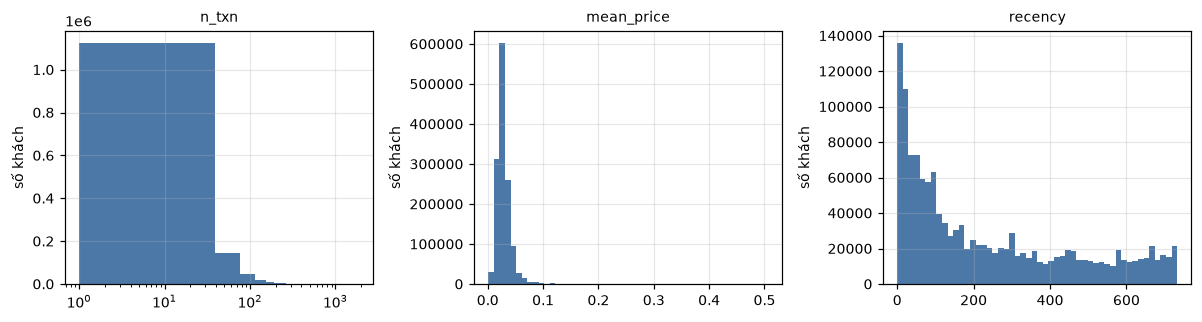

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, col, logx in [
    (axes[0], "n_txn", True),
    (axes[1], "mean_price", False),
    (axes[2], "recency", False),
]:
    vals = base[col].drop_nulls().to_numpy()
    vals = vals[vals > 0] if logx else vals
    ax.hist(vals, bins=50, color="#4C78A8")
    if logx:
        ax.set_xscale("log")
    ax.set_title(col, fontsize=9)
    ax.set_ylabel("số khách")
plt.tight_layout()
plt.show()

### Nhóm 3 — Tỷ trọng mua theo category

Với mỗi cột category, ta đếm số lượt mua của khách trong từng nhóm rồi chia cho tổng số giao dịch:

$$\text{share}(u, c) = \frac{\#\{(u, c)\}}{\#u}$$

Ví dụ: khách mua 100 món, 40 món thuộc `Baby/Children` → `index_group_name__1 = 0.4`.

Lưu dạng **ma trận thưa CSR** (`scipy.sparse`) vì mỗi khách chỉ chạm ~4–8 nhóm trong tổng 13–21 nhóm.

  index_group_name: 6 categories, nnz=2,962,749


  index_name: 13 categories, nnz=4,115,846


  garment_group_name: 16 categories, nnz=7,391,364


  section_name: 16 categories, nnz=4,985,129


  product_type_name: 21 categories, nnz=7,938,709


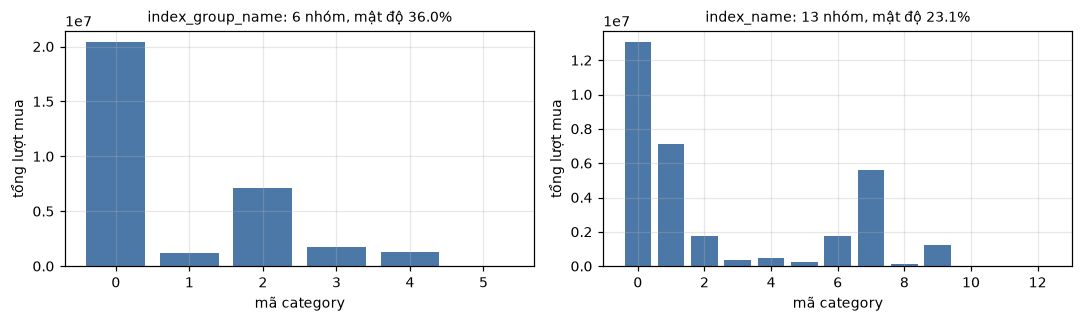

In [5]:
cats = category_counts(articles_enc)

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, (col, (mat, names)) in zip(axes, list(cats.items())[:2]):
    density = mat.nnz / (mat.shape[0] * mat.shape[1])
    ax.bar(range(mat.shape[1]), np.asarray(mat.sum(axis=0)).ravel(), color="#4C78A8")
    ax.set_title(f"{col}: {mat.shape[1]} nhóm, mật độ {density:.1%}", fontsize=9)
    ax.set_xlabel("mã category")
    ax.set_ylabel("tổng lượt mua")
plt.tight_layout()
plt.show()

### Nhóm 4 (chuẩn bị) — Ma trận khách × sản phẩm

Đây là **đầu vào quan trọng nhất** cho target encoding ở notebook 03: 27,3 triệu cặp
(khách, sản phẩm) khác nhau, lưu thưa (trung bình ~20 sản phẩm/khách).

Song song, `articles_levels.parquet` lưu mã phân loại **đầy đủ** (không gộp OTHER) cho
`department_no` (627 mức), `product_type_no` (647), `section_name` (594)...
để encoding ở nhiều mức.

In [6]:
cust_article_matrix()
levels = pl.read_parquet(C.ARTIFACTS / "articles_levels.parquet")
level_sizes = level_counts(levels)

mat = sparse.load_npz(C.ARTIFACTS / "cust_article.npz")
print(
    f"cust × article: {mat.shape}, nnz = {mat.nnz:,}, "
    f"trung bình {mat.nnz / mat.shape[0]:.1f} sản phẩm/khách"
)
print("mức phân loại:", level_sizes)

  cust x article: nnz=27,306,439


  c_department_no: 627 levels, nnz=13,676,250


  c_product_type_no: 647 levels, nnz=10,383,456


  c_index_group_name: 7 levels, nnz=2,962,749


  c_index_name: 11 levels, nnz=4,115,846


  c_garment_group_name: 32 levels, nnz=7,743,453


  c_section_name: 594 levels, nnz=8,369,256


  c_product_type_name: 645 levels, nnz=10,383,379


cust × article: (1371980, 105540), nnz = 27,306,439, trung bình 19.9 sản phẩm/khách
mức phân loại: {'c_department_no': 627, 'c_product_type_no': 647, 'c_index_group_name': 7, 'c_index_name': 11, 'c_garment_group_name': 32, 'c_section_name': 594, 'c_product_type_name': 645}


In [7]:
# Kiểm tra chéo: tổng lượt mua theo category phải bằng n_txn của từng khách
ig = sparse.load_npz(C.ARTIFACTS / "cat_counts_index_group_name.npz")
row_sums = np.asarray(ig.sum(axis=1)).ravel()
n_txn = base.sort("cust_int")["n_txn"].to_numpy()

both = (row_sums > 0) | (n_txn > 0)
print(f"khách có giao dịch: {(n_txn > 0).sum():,} | khách có trong ma trận category: {(row_sums > 0).sum():,}")
print(f"sai lệch tổng lượt mua: {np.abs(row_sums[both] - n_txn[both]).max():.0f} (phải = 0)")
print(f"khách không mua gì (n_txn = 0): {(n_txn == 0).sum():,} — mô hình vẫn phải dự đoán cho họ")

khách có giao dịch: 1,362,281 | khách có trong ma trận category: 1,362,281
sai lệch tổng lượt mua: 0 (phải = 0)
khách không mua gì (n_txn = 0): 9,699 — mô hình vẫn phải dự đoán cho họ


## Đóng gói ma trận đặc trưng tĩnh

96 đặc trưng tĩnh (24 + 4 + 72, bỏ các cột hằng/trùng) được ghi thành một file `.npy` **float32**
và mở lại bằng **memmap** khi train — nhờ vậy không chiếm RAM thường trực.

| File | Nội dung |
|---|---|
| `artifacts/X.npy` | 1.371.980 × 96, float32 (~502 MB, memmap) |
| `artifacts/X_columns.json` | tên 96 cột |
| `artifacts/y_age.npy` | nhãn `age` (NaN ở 15.861 dòng thiếu) |

In [8]:
from src.dataset import build, load

n, names = build()
X, y, feature_names = load()
print(f"X: {X.shape} ({X.dtype}) | features: {len(names)}")
print(f"nhãn có giá trị: {(~np.isnan(y)).sum():,} | thiếu: {np.isnan(y).sum():,}")
print("5 cột đầu:", feature_names[:5])
print("5 cột cuối:", feature_names[-5:])

X: (1371980, 96) (float32) | features: 96
nhãn có giá trị: 1,356,119 | thiếu: 15,861
5 cột đầu: ['active_flag', 'n_txn', 'n_uniq_art', 'total_spend', 'mean_price']
5 cột cuối: ['product_type_name__16', 'product_type_name__17', 'product_type_name__18', 'product_type_name__19', 'product_type_name__20']


## Tóm tắt

| Artifact | Kích thước | Dùng ở đâu |
|---|---|---|
| `customer_base_features.parquet` | 1.371.980 × 28 | notebook 04 |
| `X.npy` (memmap) | 1.371.980 × 96 | notebook 03, 04 |
| `cat_counts_*.npz` | 5 ma trận thưa | notebook 04 (tỷ trọng) |
| `cust_article.npz` | 27,3M nnz | notebook 03 (target encoding article) |
| `lvl_c_*.npz` | 6 ma trận thưa | notebook 03 (encoding nhiều mức) |
| `articles_levels.parquet` | 105.542 × 8 | ánh xạ mã → tên |

➡️ Tiếp theo: **03_target_encoding.ipynb** — biến "món gì được mua" thành feature mà không rò rỉ nhãn.